In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import json
import re
import matplotlib.pyplot as plt
from pathlib import Path
from pypalettes import load_cmap

In [2]:
current_path = Path.cwd()
project_root = next(
    (
        path
        for path in (current_path, *current_path.parents)
        if (path / "data" / "raw" / "listings.csv").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing data/raw/listings.csv")

df = pd.read_csv(project_root / "data" / "raw" / "listings.csv")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

Taking a look at the dataset to explore the features and look at what needs to be cleaned for the model training later.

In [3]:
print(len(df))
features_to_keep = []

13089


In [4]:
#create function for easy viewing of column name with number or unique values and NaN Values
def column_summary(columns):
    columns = pd.DataFrame({
    "Column": df[columns].columns,
    "Data type": df[columns].dtypes.astype(str).values,
    "Unique values": df[columns].nunique(dropna=True).values,
    "NaN values": df[columns].isna().sum().values,
    })
    return columns


### Scrape_meta
*listing_url* :  has the same function as id, not usefull for model <br>
*scrape_id* :  and last_scraped have values that do not provide any info (two close dates)<br>
*source* :  seems to be wether the listing was available at the date of search, if not the link was collected from the previous scrape, so it propably only reflects if the host took down the listing for a while <br>
*id* : only unique values so no double listings <br><br>
Not any feature worth keeping for model training

In [5]:
scrape_meta = [
    'id', 'listing_url', 'scrape_id', 'last_scraped', 'source'
]
print(column_summary(scrape_meta))
print('\n', df['last_scraped'].value_counts())
print('\n', df['source'].value_counts())
scrape_meta = ['id']

         Column Data type  Unique values  NaN values
0            id     int64          13089           0
1   listing_url       str          13089           0
2     scrape_id     int64              1           0
3  last_scraped       str              2           0
4        source       str              1        8572

 last_scraped
2026-09-27    10548
2026-09-26     2541
Name: count, dtype: int64

 source
previous scrape    4517
Name: count, dtype: int64


In [6]:
df.loc[df["source"] == "previous scrape", "price"].isna().value_counts()
df.loc[df["source"] == "previous scrape", 'price_quote_checkin_date'].value_counts().sort_index()
df.loc[df["source"] != "previous scrape", 'price_quote_checkin_date'].value_counts().sort_index()

price_quote_checkin_date
2026-09-27    1346
2026-09-28    1218
2026-09-29     735
2026-09-30     531
2026-10-01     465
2026-10-02     276
2026-10-03      76
2026-10-04     332
2026-10-05     159
2026-10-06      60
2026-10-07      54
2026-10-08      82
2026-10-09     119
2026-10-10      35
2026-10-11      54
2026-10-12      79
2026-10-13      33
2026-10-14      29
2026-10-15      43
2026-10-16      91
2026-10-17      28
2026-10-18      35
2026-10-19      44
2026-10-20      18
2026-10-21      16
2026-10-22      22
2026-10-23      47
2026-10-24      21
2026-10-25      21
2026-10-26      22
2026-10-27       7
2026-10-28      12
2026-10-29      23
2026-10-30      55
2026-10-31      46
2026-11-01     182
2026-11-02      31
2026-11-03      16
2026-11-04      14
2026-11-05      18
2026-11-06      38
2026-11-07      14
2026-11-08      16
2026-11-09      25
2026-11-10       6
2026-11-11       8
2026-11-12      13
2026-11-13      15
2026-11-14      13
2026-11-15      18
2026-11-16      20
2026-1

### Host_listing_desc
All of the values are subjective descriptions by the host about the listing, not really useful for the model <br><br>
No features worth keeping

In [7]:
host_listing_desc = [
    'name', 'description', 'neighborhood_overview', 'picture_url'
]
print(column_summary(host_listing_desc), '\n')
for i in host_listing_desc:
    print(df[i].head(2))

                  Column Data type  Unique values  NaN values
0                   name       str          12132           0
1            description       str          12413          31
2  neighborhood_overview   float64              0       13089
3            picture_url       str          12937           0 

0    Charming apartment, Oslo Center, Ro
1     Central big room - ap with balcony
Name: name, dtype: str
0    <b>The space</b><br />Charming apartment, Oslo...
1    A bargain in Oslo!!<br />Room in new and fully...
Name: description, dtype: str
0   NaN
1   NaN
Name: neighborhood_overview, dtype: float64
0    https://a0.muscache.com/pictures/miso/Hosting-...
1    https://a0.muscache.com/pictures/468893/9c8190...
Name: picture_url, dtype: str


### Host profile
Lot of feature with just NaN<br>
Some feature could be usefull, but are likely to be hard to access for the user. Better to focus of the house/apt itself<br>
Profile pic and indentify verified can give an idea of the safety of a listing and wether a user would book, but is not likely to affect the price<br><br>

Not using any of the features

In [8]:
host_profile = [
    'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
    'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
    'host_location', 'host_about', 'host_thumbnail_url', 'host_picture_url',
    'host_neighbourhood', 'host_verifications', 'host_has_profile_pic',
    'host_identity_verified'
]
print(column_summary(host_profile))
print((df['host_identity_verified'].value_counts()))
print((df['host_has_profile_pic'].value_counts()))

                       Column Data type  Unique values  NaN values
0                     host_id     int64          11478           0
1                    host_url       str          11478           0
2             host_profile_id     int64          11478           0
3            host_profile_url       str          11478           0
4                   host_name       str           4348           0
5                  host_since   float64              0       13089
6    hosts_time_as_user_years     int64             17           0
7   hosts_time_as_user_months     int64             12           0
8               host_location       str            254        2436
9                  host_about       str           3572        8488
10         host_thumbnail_url   float64              0       13089
11           host_picture_url       str          10961           0
12         host_neighbourhood   float64              0       13089
13         host_verifications   float64              0       1

In [9]:
print(df.loc[df['price'].notna(), 'host_identity_verified'].value_counts())
print(df.loc[df['price'].notna(), 'host_has_profile_pic'].value_counts())

host_identity_verified
t    8672
f      51
Name: count, dtype: int64
host_has_profile_pic
t    8217
f     506
Name: count, dtype: int64


### Host_hosting
Even if some of these features are interesting, such as how many listings a host has (could lower price), they are not accessible to the user therefore not relevant <br>
If a host is superhost could be an indicator of a good or lower price (often booked and users are happy). However it is not really a explaination of price rather a result of price <br><br>

Keeping superhost for now since it might indicate lower prices etc, would need to be mapped to binary values instead of string

In [10]:
host_hosting = [
    'hosts_time_as_host_years', 'hosts_time_as_host_months',
    'host_response_time', 'host_response_rate', 'host_acceptance_rate',
    'host_is_superhost', 'host_listings_count', 'host_total_listings_count',
    'calculated_host_listings_count',
    'calculated_host_listings_count_entire_homes',
    'calculated_host_listings_count_private_rooms',
    'calculated_host_listings_count_shared_rooms'
]
print(column_summary(host_hosting))

                                          Column Data type  Unique values  \
0                       hosts_time_as_host_years     int64             16   
1                      hosts_time_as_host_months     int64             12   
2                             host_response_time   float64              0   
3                             host_response_rate   float64              0   
4                           host_acceptance_rate   float64              0   
5                              host_is_superhost       str              2   
6                            host_listings_count     int64             36   
7                      host_total_listings_count   float64              0   
8                 calculated_host_listings_count     int64             21   
9    calculated_host_listings_count_entire_homes     int64             20   
10  calculated_host_listings_count_private_rooms     int64             13   
11   calculated_host_listings_count_shared_rooms     int64              8   

In [11]:
print(df['host_is_superhost'].value_counts())
features_to_keep.append('host_is_superhost')


host_is_superhost
f    10857
t     2232
Name: count, dtype: int64


### Location
Of the neighbourhood feature only cleansed contain actual values <br>
Latitude ang longitude might be interesting to look at, but might need to be transformed into some other type of values, like distance from centre (Oslo s for example) or calculating the mean price of the 10 neares neighbours. This would have to be calculated in each fold to prevent leakage. The transformation would be needed for linear regression but a random forest or gradient boosting could take the raw datavalues<br><br>
Keeping the neighbourhoods /districs and latitude and longitude (for now)

In [12]:

location = [
    'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed',
    'latitude', 'longitude'
]
print(column_summary(location))
for i in ('neighbourhood_cleansed', 'latitude', 'longitude'):
    features_to_keep.append(i)
print(features_to_keep)

                         Column Data type  Unique values  NaN values
0                 neighbourhood   float64              0       13089
1        neighbourhood_cleansed       str             17           0
2  neighbourhood_group_cleansed   float64              0       13089
3                      latitude   float64           9339           0
4                     longitude   float64          10612           0
['host_is_superhost', 'neighbourhood_cleansed', 'latitude', 'longitude']


###  Property details
Simplify by looking only at entire property listings:<br>
*property_type* : some outlier properties whos listings should be removed (tent/ shipping container etc). Manually divide into house and apartment listings<br>
*room_type* : becomes obsolete when only looking at entire listings <br>
*bathrooms_text* : has string values, integer values must be extracted, should also remove listings with no bathrooms<br>
There is some dependency between *beds*, *bedrooms*, *accomodates* and *bathrooms*, which is not really surprising. We can still keep the variables for th cleaned dataset but must be aware that the coeffs from linreg cannot be trusted as they can come from another variable. Random forest and gradient boosting are not as sensitive to dependent features for prediction. <br>
*amenities* : interesting as it could give a indication of size of space not covered by the other features, such as a bathtub would indicate a larger bathroom. However there are so many and they are enetered by the host so they are not reliable data as some host might not think to include certain amenities even though they have the. Could provide more noise than certainty<br><br>


Keeping property type, bathrooms_text, beds, bedrooms, accomodates for now



In [13]:
property_details = [
    'property_type', 'room_type', 'accommodates', 'bathrooms',
    'bathrooms_text', 'bedrooms', 'beds', 'amenities'
]
print(column_summary(property_details))


           Column Data type  Unique values  NaN values
0   property_type       str             46           0
1       room_type       str              3           0
2    accommodates     int64             16           0
3       bathrooms   float64              0       13089
4  bathrooms_text       str             19          17
5        bedrooms   float64              9           5
6            beds   float64             14         282
7       amenities       str          12342           0


In [14]:
#for the sake of analyzing remaining data we will make a column with is house and is apartment
print(df['property_type'].value_counts())

house_types = ["Entire home", "Entire townhouse", "Entire villa", "Entire guesthouse", "Tiny home", "Entire cabin", 
            "Entire chalet", "Entire cottage", "Entire bungalow", "Entire vacation home","Casa particular"]
apt_types = ["Entire rental unit", "Entire condo", "Entire loft", "Entire serviced apartment", "Entire guest suite"]

df["is_house"] = df['property_type'].isin(house_types).astype(int)
df["is_apt"] = df['property_type'].isin(apt_types).astype(int)


property_type
Entire rental unit                    7944
Entire condo                          2470
Entire home                            828
Private room in rental unit            798
Private room in condo                  327
Private room in home                   141
Entire townhouse                       105
Entire loft                             96
Shared room in rental unit              62
Entire villa                            56
Entire serviced apartment               48
Entire guest suite                      24
Entire guesthouse                       20
Camper/RV                               18
Private room in loft                    17
Private room in bed and breakfast       17
Private room in townhouse               17
Tiny home                               13
Private room in villa                   11
Entire cabin                             9
Private room in guesthouse               8
Boat                                     6
Room in aparthotel                      

In [15]:
print(df['room_type'].value_counts(), '\n')
print(df.loc[df['is_house'] == 1, 'room_type'].value_counts(), '\n')
print(df.loc[df['is_apt'] == 1, 'room_type'].value_counts())

room_type
Entire home/apt    11651
Private room        1368
Shared room           70
Name: count, dtype: int64 

room_type
Entire home/apt    1039
Name: count, dtype: int64 

room_type
Entire home/apt    10582
Name: count, dtype: int64


In [16]:
table = pd.DataFrame({
    'acc_values' : df['accommodates'].value_counts().sort_index(), 
    'acc_house' : df.loc[df['is_house'] == 1, 'accommodates'].value_counts().sort_index(),
    'acc_apt' : df.loc[df['is_apt'] == 1, 'accommodates'].value_counts().sort_index()
})
print(table)

              acc_values  acc_house  acc_apt
accommodates                                
1                    639        NaN    152.0
2                   4802       50.0   3954.0
3                   1595       22.0   1503.0
4                   3412      116.0   3229.0
5                    948      130.0    799.0
6                    956      304.0    645.0
7                    219      108.0    109.0
8                    305      183.0    108.0
9                     69       42.0     27.0
10                    86       50.0     35.0
11                    16       11.0      5.0
12                    23       14.0      9.0
13                     1        1.0      NaN
14                     3        2.0      1.0
15                    10        3.0      5.0
16                     5        3.0      1.0


In [17]:
print(df['bathrooms_text'].value_counts(), '\n')
df["bathrooms_int"] = df["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)
df.loc[df["bathrooms_text"] == "Half-bath", "bathrooms_int"] = 0.5

#look at bathrooms_int for is house and is apt since there are som 0 values
table = pd.DataFrame({
    'Bathrooms dataset' : df['bathrooms_int'].value_counts().sort_index(),
    'Bathrooms houses' :  df.loc[df['is_house'] == 1, 'bathrooms_int'].value_counts().sort_index(),
    'Bathrooms apt' : df.loc[df['is_apt'] == 1, 'bathrooms_int'].value_counts().sort_index()
})
print(table)

bathrooms_text
1 bath               9968
2 baths               910
1 shared bath         827
1.5 baths             580
1 private bath        195
2.5 baths             161
Shared half-bath       76
2 shared baths         71
1.5 shared baths       64
3 baths                62
0 baths                50
Half-bath              28
3.5 baths              19
2.5 shared baths       18
Private half-bath      13
0 shared baths         11
4 baths                 9
3 shared baths          6
4 shared baths          4
Name: count, dtype: int64 

               Bathrooms dataset  Bathrooms houses  Bathrooms apt
bathrooms_int                                                    
0.0                           61                 3             42
0.5                           28                 3             11
1.0                        10990               270           9610
1.5                          644               185            374
2.0                          981               371            511
2

In [18]:
print(df.loc[(df['bathrooms_int'] == 0) & (df['is_apt'] == 1), 'property_type'].value_counts())


property_type
Entire rental unit    34
Entire condo           8
Name: count, dtype: int64


In [19]:
table = pd.DataFrame({
    'beds' : df['beds'].value_counts().sort_index(),
    'bedrooms' : df['bedrooms'].value_counts().sort_index()
})
print(table)


        beds  bedrooms
0.0      NaN     594.0
1.0   5949.0    6966.0
2.0   4020.0    3610.0
3.0   1552.0    1293.0
4.0    720.0     499.0
5.0    313.0     104.0
6.0    136.0      16.0
7.0     53.0       1.0
8.0     44.0       NaN
9.0      7.0       NaN
10.0     8.0       1.0
11.0     1.0       NaN
12.0     2.0       NaN
13.0     1.0       NaN
14.0     1.0       NaN


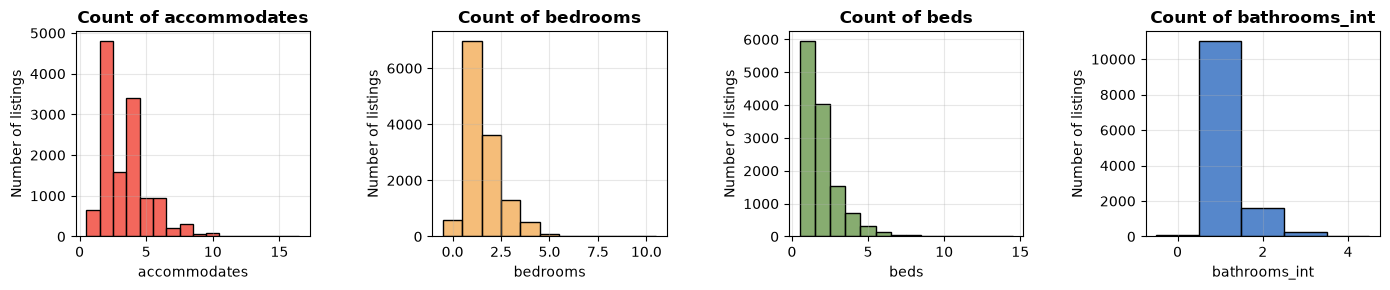

In [20]:
#plotting the distribution of accomodates, bedrooms, beds and bathrooms
vars = ['accommodates', 'bedrooms', 'beds', 'bathrooms_int']
cmap = load_cmap("CarolMan")

fig, axes = plt.subplots(1,4,figsize=(14,3))

for i, (var, ax) in enumerate(zip(vars, axes)):
    sns.histplot(data = df, x = var, ax = ax, discrete = True, color = cmap(i),  alpha = 0.7)
    ax.set_title(f'Count of {var}', weight = 'bold')
    ax.set_xlabel(var)
    ax.set_ylabel('Number of listings')
    ax.grid(alpha = 0.3)
plt.tight_layout(h_pad=3, w_pad=3)

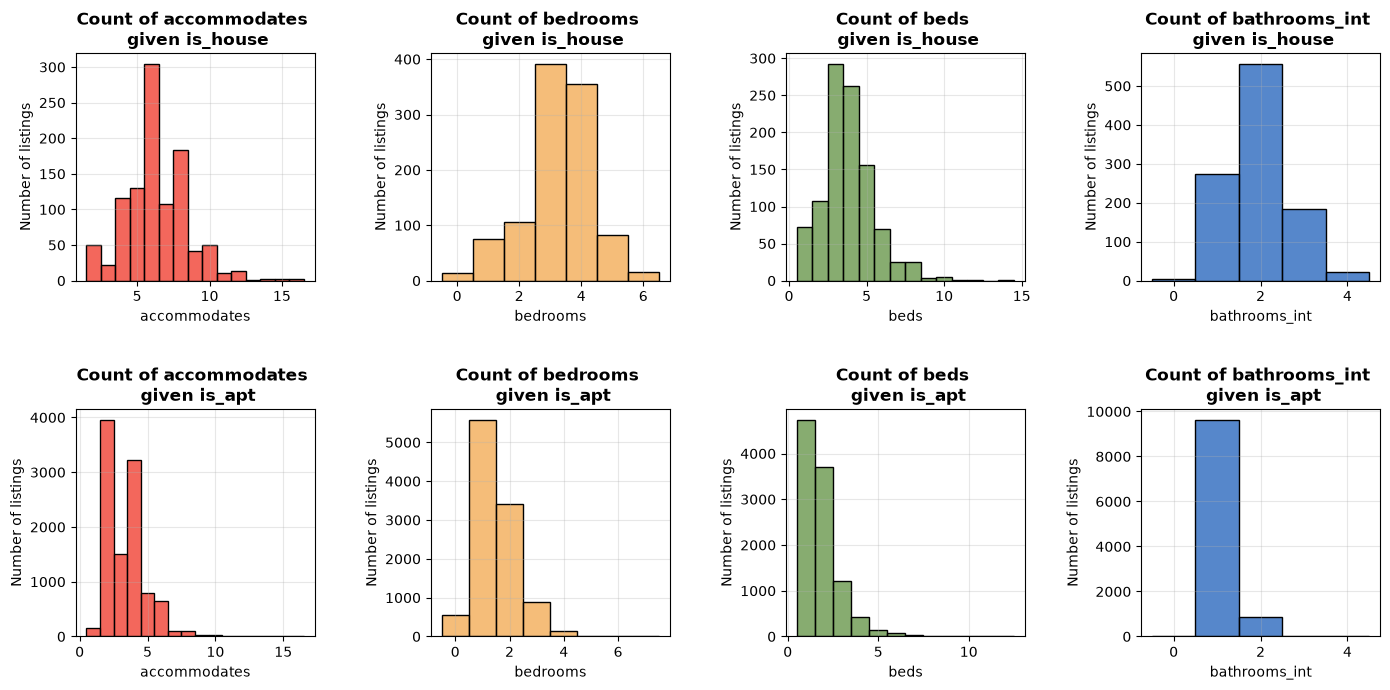

In [21]:
#look at the distribution of beds, bedrooms, accomodates and bathrooms with the dataset split into house and apt
property_type = ['is_house', 'is_apt']

fig, axes = plt.subplots(2,4, figsize = (14,7))

for row, prop in enumerate(property_type):
    for i, var in enumerate(vars):
        ax = axes[row, i]
        sns.histplot(data = df.loc[df[prop] == 1], x = var, ax = ax, discrete = True, color = cmap(i), alpha = 0.7 )
        ax.set_title(f'Count of {var} \n given {prop}', weight = 'bold')
        ax.set_ylabel('Number of listings')
        ax.set_xlabel(var)
        ax.grid(alpha = 0.3)

plt.tight_layout(h_pad = 3, w_pad = 3)

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


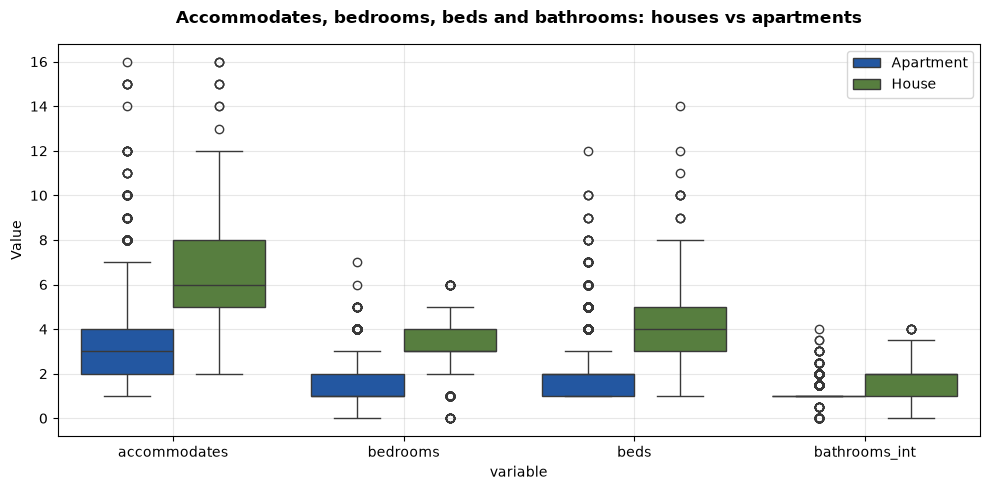

In [22]:
plot_df = df.loc[(df['is_house'] == 1) | (df['is_apt'] == 1), vars].copy()
plot_df['type'] = np.where(df.loc[plot_df.index, 'is_house'] == 1, 'House', 'Apartment')

long_df = plot_df.melt(id_vars='type', var_name='variable', value_name='value')

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=long_df, x='variable', y='value', hue='type', ax=ax, 
            palette={'House': cmap(2), 'Apartment': cmap(3)})
ax.set_title('Accommodates, bedrooms, beds and bathrooms: houses vs apartments', weight='bold', pad = 15)
ax.set_ylabel('Value')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(h_pad = 10, w_pad = 3)
plt.show()


/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


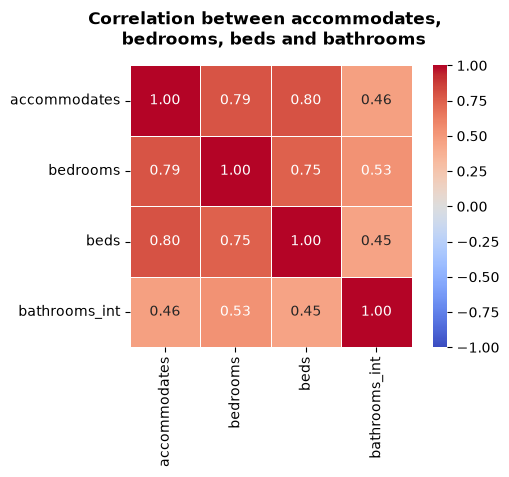

In [23]:
#lets look at the relations between the features as there is a high likelyhood of them being dependent on eachother
corr = df[vars].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, center=0,
            linewidths=0.5, square=True, ax=ax)
ax.set_title('Correlation between accommodates,  \n bedrooms, beds and bathrooms',
             weight='bold', pad=15)
ax.tick_params(axis='y', labelrotation=0)   
ax.tick_params(axis='x', labelrotation=90)  
plt.tight_layout(pad=2)
plt.show()

In [24]:
print(df['amenities'].head(3))

df['amenities_list'] = df['amenities'].apply(json.loads)
entire_spaces = (df['is_house'] == 1) | (df['is_apt'] == 1)
df_amenities = df.loc[entire_spaces, 'amenities_list'].copy()

print(df_amenities.explode().nunique(), len(df_amenities), '\n')
print(df_amenities.explode().value_counts().head(10))       #splits amenities into columns to count them

0    ["City skyline view", "Dishes and silverware",...
1    ["Extra pillows and blankets", "Dishes and sil...
2    ["City skyline view", "Dishes and silverware",...
Name: amenities, dtype: str
2607 11621 

amenities_list
Kitchen                  11420
Smoke alarm              11241
Wifi                     10918
Fire extinguisher        10345
Washer                    8592
Hot water                 8386
TV                        8061
Refrigerator              7568
Dishes and silverware     7531
Cooking basics            7446
Name: count, dtype: int64


In [25]:
keeping = ['property_type', 'accommodates',
    'bathrooms_text', 'bedrooms', 'beds']
for k in keeping:
    features_to_keep.append(k)

### Pricing
*price* and *price per night* are the same values with price being string. Price per night should be cleaned in terms of removing the ouliers. <br>
*checkin date* and *checkout date* are usefull for calculating the length of the stay that the price per night is based on, and we can see a clear trend of decreasing price the longer you stay. Can also specify which month the checkin date is as some months seem to be more expensive (likely due to holidays)Should remove those listing where the price is calculated from a stay longer than 31 days (the longest possible month) <br><br>

Keeping price per night, checkin and checkout date



In [26]:

pricing = [
    'price', 'price_quote_checkin_date', 'price_quote_checkout_date',
    'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw'
]
print(column_summary(pricing))

                        Column Data type  Unique values  NaN values
0                        price       str           5126        4366
1     price_quote_checkin_date       str            291        4151
2    price_quote_checkout_date       str            322        4151
3      price_quote_total_price   float64           5062        4366
4  price_quote_price_per_night   float64           5126        4366
5              price_quote_raw       str           8542        4151


In [27]:
table = pd.DataFrame({
    'price' : df['price'].head(10),
    'total_price' : df['price_quote_total_price'].head(10),
    'price_per_night' : df['price_quote_price_per_night'].head(10),
    #'raw' : df['price_quote_raw'].head(10)
})
print(table)

       price  total_price  price_per_night
0        NaN          NaN              NaN
1    $513.21      7184.95           513.21
2  $1,267.50      2535.00          1267.50
3    $984.50      1969.00           984.50
4        NaN          NaN              NaN
5  $1,586.00      1586.00          1586.00
6  $1,114.13     16712.00          1114.13
7        NaN          NaN              NaN
8    $865.00      3460.00           865.00
9        NaN          NaN              NaN


In [28]:
df['nights'] = (pd.to_datetime(df['price_quote_checkout_date'])
          - pd.to_datetime(df['price_quote_checkin_date'])).dt.days
df['nights'].value_counts().sort_index()
#probably create some kind of cutoff like <=31 days

nights
1.0      1929
2.0      3104
3.0      1766
4.0       649
5.0       520
6.0       172
7.0       297
8.0        10
9.0         8
10.0       63
11.0        3
12.0        7
13.0        7
14.0       95
15.0       28
16.0        1
17.0        2
18.0        3
20.0       27
21.0       21
22.0        1
23.0        1
24.0        1
25.0       22
26.0        3
27.0        1
28.0       22
29.0        2
30.0      113
31.0       17
32.0        1
35.0        1
40.0        2
45.0        2
48.0        1
50.0        3
60.0        9
65.0        1
80.0        1
89.0        1
90.0        9
100.0       5
180.0       1
183.0       1
200.0       2
300.0       2
365.0       1
Name: count, dtype: int64

In [29]:
checkin = pd.to_datetime(df['price_quote_checkin_date'])
month = checkin.dt.month_name()
df['checkin_month'] = month
print(df['checkin_month'].value_counts())         # same, with month names
df_short_stay = df.loc[df['nights'] <=31, ['checkin_month', 'price_quote_price_per_night', 'nights']].copy()



checkin_month
September    4045
October      2480
December      684
November      623
January       438
February      139
March         132
June          118
July           83
May            76
August         63
April          57
Name: count, dtype: int64


/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


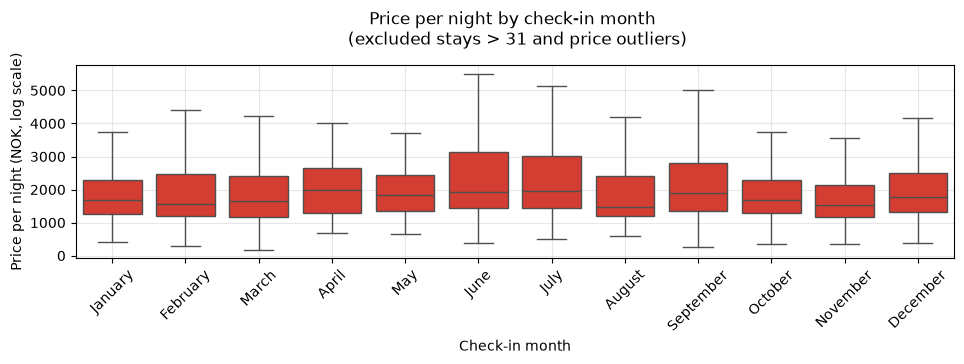

In [30]:
cutoff = df['price_quote_price_per_night'].quantile(0.99)
df_short_stay_cut = df_short_stay[df_short_stay['price_quote_price_per_night'] <= cutoff]

# Months in calendar order
order = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
         'August', 'September', 'October', 'November', 'December']

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df_short_stay_cut, x='checkin_month', y='price_quote_price_per_night', order=order,
            color=cmap(0), showfliers=False, ax=ax)

ax.set_title('Price per night by check-in month \n (excluded stays > 31 and price outliers)', pad=15)
ax.set_xlabel('Check-in month')
ax.set_ylabel('Price per night (NOK, log scale)')
ax.tick_params(axis='x', labelrotation=45)
ax.grid(alpha=0.3)
plt.tight_layout(pad=2)
plt.show()


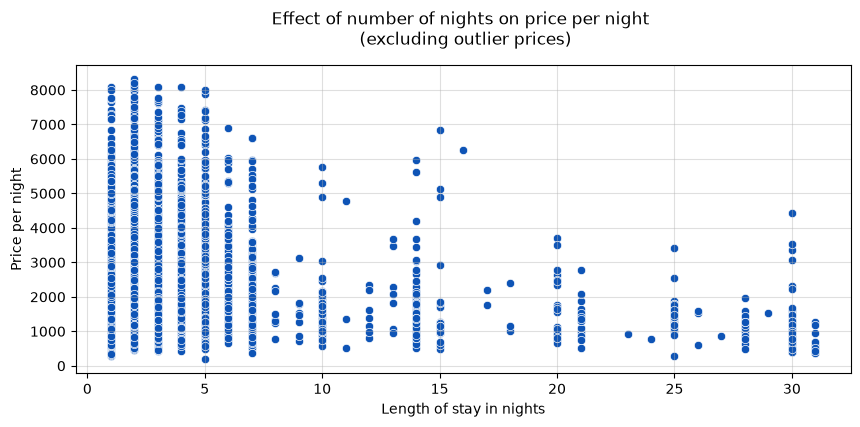

In [31]:

fig, ax = plt.subplots(figsize=(10, 4))
sns.scatterplot(data = df_short_stay_cut, x = 'nights', y='price_quote_price_per_night', color = cmap(3), ax = ax)
ax.set_title('Effect of number of nights on price per night \n (excluding outlier prices)', pad = 15)
ax.set_ylabel('Price per night')
ax.set_xlabel('Length of stay in nights')
ax.grid(alpha = 0.4)
plt.show()

In [32]:

keeping= ['price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_price_per_night']
for k in keeping:
    features_to_keep.append(k)

### Stay rules
Some of these are meta data and therefore not available for the user. Only ones that could have been interesting is minimum nights, maybe maximum too, but they do not provide much additional information to the number of nights stay values<br><br>

Keeping none

In [33]:

stay_rules = [
    'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
    'maximum_minimum_nights', 'minimum_maximum_nights',
    'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm'
]
print(column_summary(stay_rules))


                   Column Data type  Unique values  NaN values
0          minimum_nights   float64             55           2
1          maximum_nights   float64            126           2
2  minimum_minimum_nights   float64             55           2
3  maximum_minimum_nights   float64             64           2
4  minimum_maximum_nights   float64            126           2
5  maximum_maximum_nights   float64            126           2
6  minimum_nights_avg_ntm   float64            211           0
7  maximum_nights_avg_ntm   float64            165           0


### Availability
Availability might be an indicator for price, as listings that are cheap are likely to get booked often. They do not however explain the price. Also, to provide this information, if they can even access it, would be very tideous for the user. <br><br>
Keeping none

In [34]:
availability = [
    'calendar_updated', 'has_availability', 'availability_30',
    'availability_60', 'availability_90', 'availability_365',
    'availability_eoy', 'calendar_last_scraped'
]


### Reviews
A listing having many reviews is likely and indicator of a cheaper listing as more people can afford and want to book their stay with them. It is, same as for availability, not a feature that explains the price of the listing. Additionally, the scores could be influenced by price, because someone paying more would expect a higher standard. Also, new listings do not have any reviews. Therefore better to leave reviews out of the model. <br><br>
Keeping none

In [35]:
reviews = [
    'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d',
    'number_of_reviews_ly', 'first_review', 'last_review',
    'review_scores_rating', 'review_scores_accuracy',
    'review_scores_cleanliness', 'review_scores_checkin',
    'review_scores_communication', 'review_scores_location',
    'review_scores_value', 'reviews_per_month'
]

### Performance and booking
Not available to user or just NaN values<br><br>
Keeping none

In [36]:
performance_booking_legal = [
    'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'license', 'instant_bookable'
]
print(column_summary(performance_booking_legal))

                      Column Data type  Unique values  NaN values
0  estimated_occupancy_l365d     int64             83           0
1    estimated_revenue_l365d   float64           5133        4366
2                    license   float64              0       13089
3           instant_bookable   float64              0       13089


# TODO:
- looking at the relations between the features we want to keep

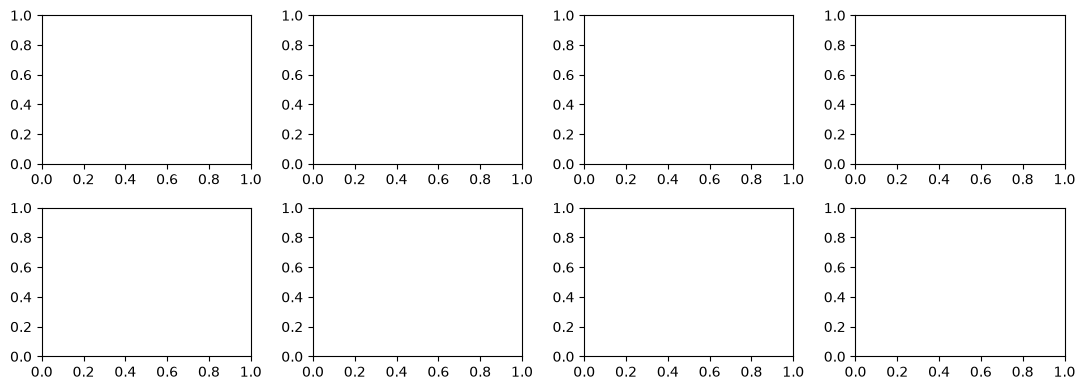

In [37]:
vars = ['accommodates', 'bedrooms', 'beds', 'bathrooms']
colors = []
fig, axes = plt.subplots(2, 4, figsize=(11, 4))
axes = axes.flatten()

for ax, var, color in zip(axes, vars, colors):
    sns.histplot(data=df_analyze, x=var, bins=15, ax=ax)
    ax.set_title(f"Histogram av {var}")
    ax.set_xlabel(var)
    ax.set_yscale('log')
    ax.set_ylabel("Antall")
    ax.grid(alpha=0.3)

plt.tight_layout()

In [38]:
constant_columns = df_clean.columns[df_clean.nunique(dropna=True) <= 1]
df_clean= df_clean.drop(columns=constant_columns).copy()

columns_to_keep = [
    "id",
    "host_is_superhost",
    "neighbourhood_cleansed",
    "latitude",
    "longitude",
    "property_type",
    "room_type",
    "accommodates",
    "bathrooms_text",
    "bedrooms",
    "beds",
    "amenities",
    "price",
    "minimum_nights",
    "maximum_nights",
    "number_of_reviews",
    "review_scores_rating",
]

df_clean = df_clean[columns_to_keep].copy()

print(f"Dropped constant/all-NaN columns: {list(constant_columns)}")
print(f"Kept columns: {columns_to_keep}")
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_clean.shape}")

NameError: name 'df_clean' is not defined

In [ ]:
column_summary = pd.DataFrame({
    "Column": df_clean.columns,
    "Unique values": df_clean.nunique(dropna=True).values,
    "NaN values": df_clean.isna().sum().values,
})

column_summary

,Column,Unique values,NaN values
0,id,13089,0
1,host_is_superhost,2,0
2,neighbourhood_cleansed,17,0
3,latitude,9339,0
4,longitude,10612,0
5,property_type,46,0
6,room_type,3,0
7,accommodates,16,0
8,bathrooms_text,19,17
9,bedrooms,9,5


In [ ]:
#checkig if id has only unique values and dropping if true
df_clean['id'].is_unique
df_clean = df_clean.drop(columns = ['id'])


In [ ]:
#replace host is superhost with 1 for true and 0 for false
df_clean["host_is_superhost"] = df_clean["host_is_superhost"].map({"t": 1, "f": 0})
df_clean["host_is_superhost"].value_counts()

host_is_superhost
0    10857
1     2232
Name: count, dtype: int64

In [ ]:
#dropping lattitude and longitude for now
df_clean = df_clean.drop(columns = ['latitude','longitude'])

In [ ]:
#Remove property types that don't fit a standard Airbnb price model
entire_space = [
    "Entire rental unit", "Entire condo", "Entire home", "Entire townhouse",
    "Entire loft", "Entire villa", "Entire serviced apartment", "Entire guest suite",
    "Entire guesthouse", "Tiny home", "Entire cabin",
]

df_clean = df_clean[df_clean["property_type"].isin(entire_space)]

#replace categories with home = 1 apt = 0 
homes = [
    "Entire home", "Entire townhouse", "Entire villa",
    "Entire guesthouse", "Tiny home", "Entire cabin",
]

df_clean["property_type"] = df_clean["property_type"].isin(homes).astype(int)
df_clean = df_clean.rename(columns={"property_type": "is_house"})
df_clean["is_house"].value_counts()


is_house
0    10582
1     1031
Name: count, dtype: int64

In [ ]:
#checking if room types is labeled correctly given we dropped propertytypes that include sharing
df_clean['room_type'].value_counts()
#drop since only entire home/apt exsist now
#df_clean = df_clean.drop(columns = ['room_type'])

room_type
Entire home/apt    11613
Name: count, dtype: int64

In [ ]:
# Pull the number out of the text, e.g. "1.5 baths" -> 1.5
df_clean["bathrooms"] = df_clean["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)

# "Half-bath" has no number, so set it to 0.5
df_clean.loc[df_clean["bathrooms_text"] == "Half-bath", "bathrooms"] = 0.5

# Remove listings with 0 bathrooms (likely data errors)
df_clean = df_clean[df_clean["bathrooms"] > 0]

df_clean = df_clean.drop(columns=["bathrooms_text"])
df_clean["bathrooms"].value_counts().sort_index()

bathrooms
0.5      14
1.0    9878
1.5     558
2.0     880
2.5     154
3.0      58
3.5      18
4.0       7
Name: count, dtype: int64

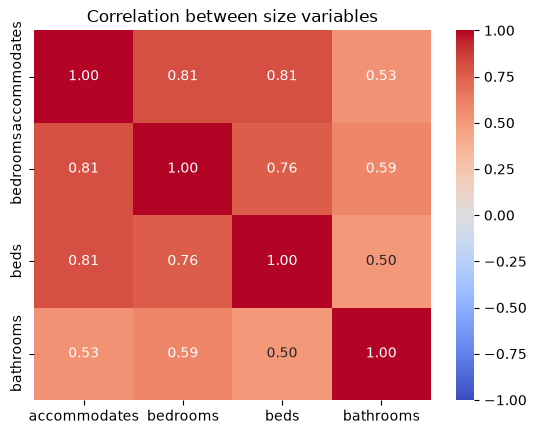

In [ ]:
cols = ["accommodates", "bedrooms", "beds", "bathrooms"]
corr = df_clean[cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between size variables")
plt.show()

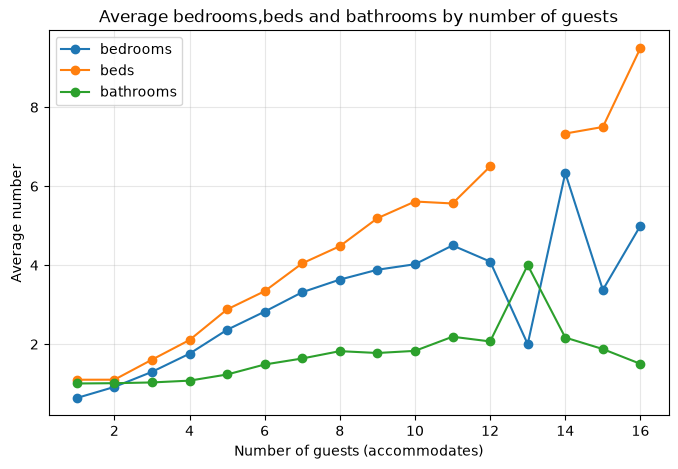

In [ ]:
avg = df_clean.groupby("accommodates")[["bedrooms", "beds", "bathrooms"]].mean()

avg.plot(marker="o", figsize=(8, 5))
plt.xlabel("Number of guests (accommodates)")
plt.ylabel("Average number")
plt.title("Average bedrooms,beds and bathrooms by number of guests")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#remove listing with 13 accomodations as it is an outlier
df_clean = df_clean[df_clean["accommodates"] != 13]

# Average known bed counts for each bedroom/accommodates combination
group_bed_average = df_clean.groupby(
    ["bedrooms", "accommodates"]
)["beds"].transform("mean")

# Use that average for missing beds, rounded to a whole bed
df_clean["beds"] = df_clean["beds"].fillna(group_bed_average).round()

#to much correlation for linear regression, we drop
#df_clean = df_clean.drop(columns = ['bedrooms', 'beds', 'bathrooms'])

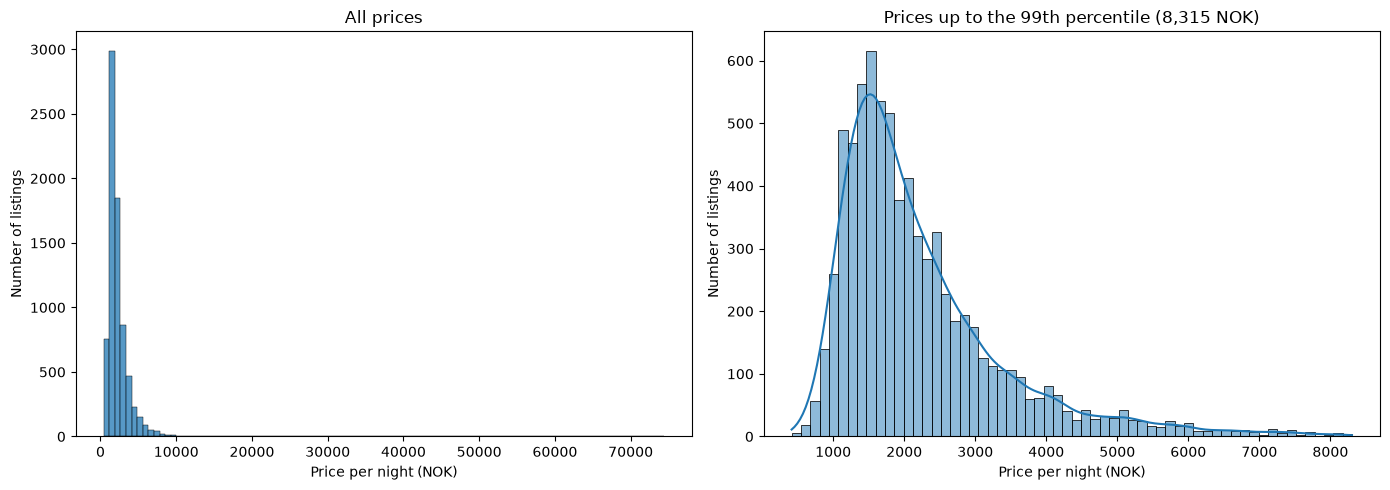

In [ ]:
# Clean price: remove $ and commas, then convert to numbers
df_clean["price"] = df_clean["price"].str.replace("[$,]", "", regex=True).astype(float)

# Remove rows with no price
df_clean = df_clean.dropna(subset=["price"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# All prices
sns.histplot(data=df_clean, x="price", bins=100, ax=axes[0])
axes[0].set_title("All prices")
axes[0].set_xlabel("Price per night (NOK)")
axes[0].set_ylabel("Number of listings")

# Zoomed in: the bottom 99% of prices
cutoff = df_clean["price"].quantile(0.99)
sns.histplot(data=df_clean[df_clean["price"] <= cutoff], x="price", bins=60, kde=True, ax=axes[1])
axes[1].set_title(f"Prices up to the 99th percentile ({cutoff:,.0f} NOK)")
axes[1].set_xlabel("Price per night (NOK)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

In [ ]:
#decide to remove all observations where price exceeds 99th percentile
cutoff = df_clean["price"].quantile(0.99)

rows_before = len(df_clean)
df_clean = df_clean[df_clean["price"] <= cutoff]

print(f"Cutoff: {cutoff:,.0f} NOK")
print(f"Removed {rows_before - len(df_clean)} rows")

#add a column with logaritmic values of price
df_clean["log_price"] = np.log(df_clean["price"])

Cutoff: 8,315 NOK
Removed 76 rows


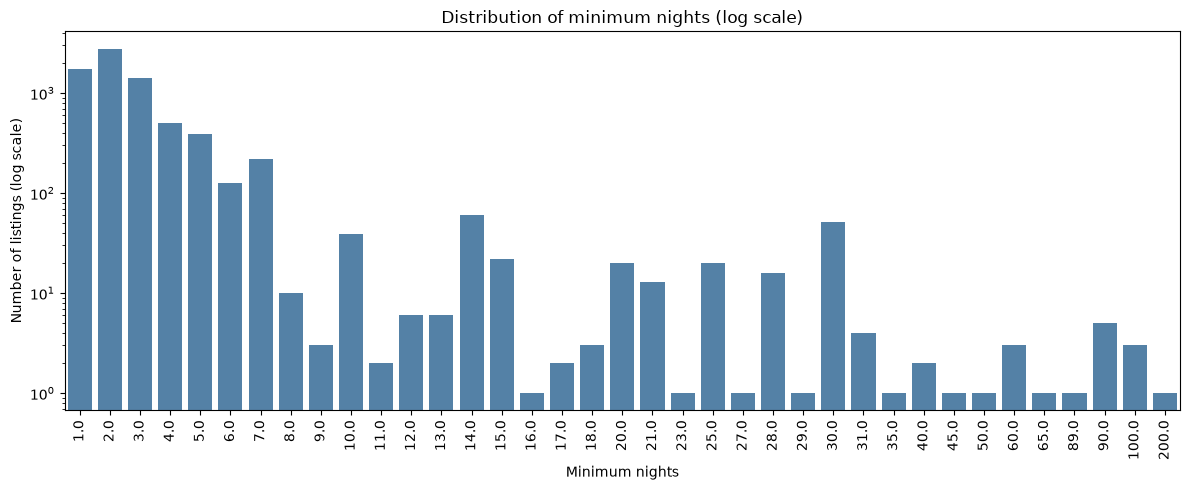

In [ ]:
#looking at minimum and maximum nights and removing outliers
plt.figure(figsize=(12, 5))
sns.countplot(data=df_clean, x="minimum_nights", color="steelblue")
plt.yscale("log")
plt.title("Distribution of minimum nights (log scale)")
plt.xlabel("Minimum nights")
plt.ylabel("Number of listings (log scale)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

df_clean = df_clean[df_clean["minimum_nights"] <= 28]

In [ ]:
#dropping maximum nights
df_clean = df_clean.drop(columns =['maximum_nights'])

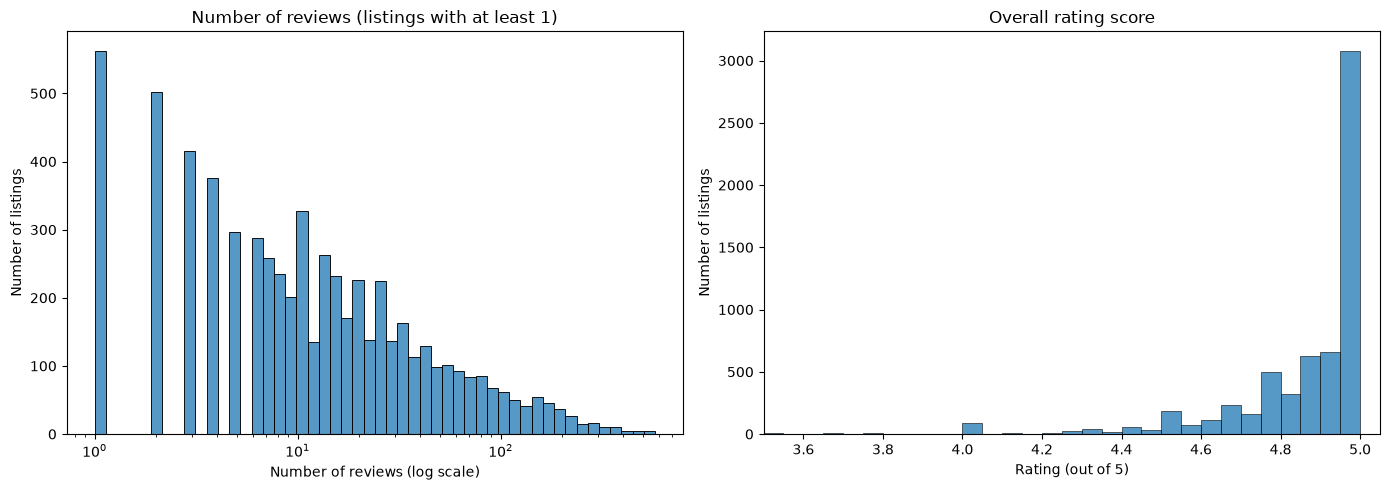

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Number of reviews: log scale on the x-axis because of a long tail
sns.histplot(data=df_clean, x="number_of_reviews", bins=50, log_scale=(True, False), ax=axes[0])
axes[0].set_title("Number of reviews (listings with at least 1)")
axes[0].set_xlabel("Number of reviews (log scale)")
axes[0].set_ylabel("Number of listings")

# Rating score: zoomed in on the range where almost all ratings fall
sns.histplot(data=df_clean, x="review_scores_rating", binwidth=0.05, ax=axes[1])
axes[1].set_xlim(3.5, 5.05)
axes[1].set_title("Overall rating score")
axes[1].set_xlabel("Rating (out of 5)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

In [ ]:
print(df_clean["number_of_reviews"].median())

7.0


In [ ]:
# Flag listings that have a rating (1) or no reviews yet (0)
df_clean["has_rating"] = df_clean["review_scores_rating"].notna().astype(int)

# Weighted rating: trust a listing's own rating more the more reviews it has
m = df_clean["number_of_reviews"].median()        # reviews needed before a rating is trusted
C = df_clean["review_scores_rating"].median()   # typical rating across all listings
v = df_clean["number_of_reviews"]
R = df_clean["review_scores_rating"]

df_clean["weighted_rating"] = (v / (v + m)) * R + (m / (v + m)) * C

# Listings with no reviews get the typical rating
df_clean["weighted_rating"] = df_clean["weighted_rating"].fillna(C)

# Check the result
print(df_clean["weighted_rating"].isna().sum())
print(df_clean["has_rating"].value_counts())
df_clean[["number_of_reviews", "review_scores_rating", "weighted_rating", "has_rating"]].head(10)

0
has_rating
1    6303
0    1106
Name: count, dtype: int64


,number_of_reviews,review_scores_rating,weighted_rating,has_rating
5,507,4.96,4.959613,1
6,24,4.88,4.897647,1
10,27,4.59,4.684595,1
11,10,4.90,4.920000,1
14,29,4.90,4.910256,1
15,2,4.50,4.866667,1
19,172,4.65,4.665934,1
21,9,4.33,4.651053,1
22,29,4.97,4.962308,1
23,98,4.82,4.831111,1


In [ ]:
df_clean.isna().sum()

host_is_superhost            0
neighbourhood_cleansed       0
is_house                     0
room_type                    0
accommodates                 0
bedrooms                     0
beds                         0
amenities                    0
price                        0
minimum_nights               0
number_of_reviews            0
review_scores_rating      1106
bathrooms                    0
log_price                    0
has_rating                   0
weighted_rating              0
dtype: int64

In [ ]:
cols = ['host_is_superhost', 'neighbourhood_cleansed', 'is_house', 'room_type', 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'number_of_reviews', 'has_rating']
for col in cols:
    print(df_clean[col].value_counts().sort_index())
    print('\n')

host_is_superhost
0    5989
1    1420
Name: count, dtype: int64


neighbourhood_cleansed
Alna                  116
Bjerke                184
Frogner              1115
Gamle Oslo           1288
Grorud                 43
Grünerløkka          1419
Marka                  28
Nordre Aker           284
Nordstrand            348
Sagene                796
Sentrum               139
St. Hanshaugen        870
Stovner                31
Søndre Nordstrand      83
Ullern                229
Vestre Aker           247
Østensjø              189
Name: count, dtype: int64


is_house
0    6733
1     676
Name: count, dtype: int64


room_type
Entire home/apt    7409
Name: count, dtype: int64


accommodates
1      110
2     2473
3      954
4     2143
5      586
6      625
7      156
8      209
9       51
10      64
11      11
12      15
14       3
15       7
16       2
Name: count, dtype: int64


bedrooms
0.0     351
1.0    3589
2.0    2237
3.0     827
4.0     332
5.0      61
6.0      11
7.0       1
Name: count

In [ ]:
features_for_analyzing = ['host_is_superhost', 'neighbourhood_cleansed', 'is_house', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'price', 'minimum_nights', 'log_price', 'has_rating', 'weighted_rating']
df_analyze = df_clean[features_for_analyzing]
#df_analyze.to_csv(project_root / "data" / "processed" / "listings_clean.csv", index=False)
df_analyze.head()

,host_is_superhost,neighbourhood_cleansed,is_house,accommodates,bedrooms,beds,bathrooms,price,minimum_nights,log_price,has_rating,weighted_rating
5,1,Nordstrand,0,6,2.0,3.0,1.0,1586.00,1.0,7.368970,1,4.959613
6,0,Sagene,0,2,1.0,1.0,1.0,1114.13,15.0,7.015829,1,4.897647
10,0,Grünerløkka,0,2,1.0,1.0,1.0,1280.15,3.0,7.154733,1,4.684595
11,0,Grünerløkka,0,5,4.0,3.0,1.5,3700.00,4.0,8.216088,1,4.920000
14,0,Grünerløkka,0,2,1.0,1.0,1.0,1702.00,3.0,7.439559,1,4.910256
